=== Перші рядки датасету ===
  Movie ID  Action  Adventure  Animation  Children  Comedy  Crime  \
0  b'3107'       1          0          0         0       0      0   
1  b'2114'       0          0          0         0       0      0   
2   b'256'       0          0          0         0       1      0   
3  b'1389'       1          0          0         0       0      0   
4  b'3635'       1          0          0         0       0      0   

   Documentary  Drama  Fantasy  ...  Unknown  War  Western  \
0            0      1        0  ...        0    0        0   
1            0      1        0  ...        0    0        0   
2            0      0        0  ...        0    0        0   
3            0      0        0  ...        0    0        0   
4            0      0        0  ...        0    0        0   

   (no genres listed)  User ID  Age  Gender  Occupation   Zipcode  Rating  
0                   0   b'130'   35       1          18  b'50021'       5  
1                   0  b'3829' 

C:\Users\Вейдер\AppData\Local\Temp\ipykernel_22612\444225669.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = data.select_dtypes(include=["object"]).columns


Очищення завершено успішно!

Топ кореляцій з рейтингом (Rating):
Rating         1.000000
Drama          0.122561
War            0.075688
Film-Noir      0.060259
Age            0.056869
Crime          0.033446
Documentary    0.028098
Animation      0.019670
Mystery        0.015848
Musical        0.015643
Name: Rating, dtype: float64

Розмір навчальної вибірки: (800167, 21)
Розмір тестової вибірки: (200042, 21)

--- Лінійна регресія ---
Коефіцієнт детермінації (R^2): 0.0380
Середньоквадратична помилка (MSE): 1.1964


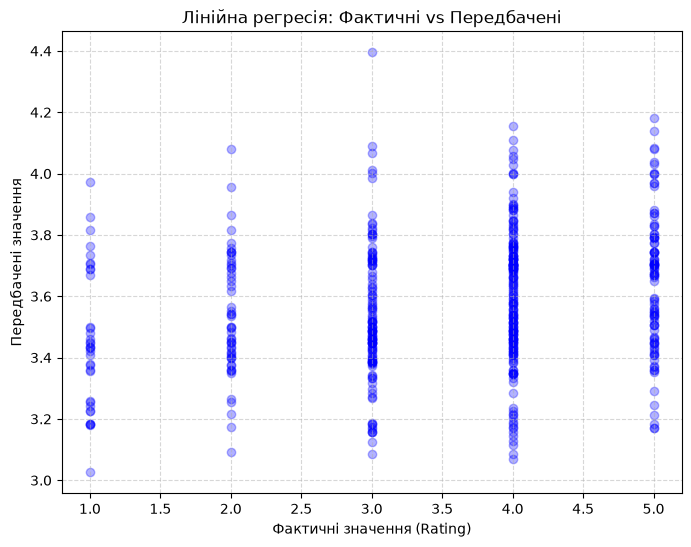


--- Порівняння з іншими алгоритмами регресії ---
Ridge R^2: 0.0380 | MSE: 1.1964
Lasso R^2: 0.0246 | MSE: 1.2131
Decision Tree R^2: 0.0357 | MSE: 1.1993


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error

# --- 1. ЗАВАНТАЖЕННЯ ДАНИХ ---
data = pd.read_csv("movielens1m.csv")
print("=== Перші рядки датасету ===")
print(data.head())
print("\nІнформація про датасет:")
print(data.info())

# --- 2. ПОПЕРЕДНЯ ОБРОБКА ДАНИХ ---
# Перевірка наявності пропущених значень
missing_values = data.isnull().sum()
print("Пропущені значення:")
print(missing_values[missing_values > 0])

# 1. Заповнюємо пропуски в числових стовпцях їхнім середнім значенням (.mean())
numeric_cols = data.select_dtypes(include=[np.number]).columns
data[numeric_cols] = data[numeric_cols].fillna(data[numeric_cols].mean())

# 2. Заповнюємо пропуски в категоріальних/текстових стовпцях найчастішим значенням (модою)
object_cols = data.select_dtypes(include=["object"]).columns
for col in object_cols:
    if not data[col].mode().empty:
        data[col] = data[col].fillna(data[col].mode()[0])

# Видалення дублікатів
data.drop_duplicates(inplace=True)
print("Очищення завершено успішно!")

# Базовий аналіз кореляцій з цільовою змінною 'Rating'
numeric_data = data.select_dtypes(include=["number"])
correlation = numeric_data.corr()
print("\nТоп кореляцій з рейтингом (Rating):")
print(correlation["Rating"].sort_values(ascending=False).head(10))

# --- 3. РОЗПОДІЛ ДАНИХ ---
# Вибираємо числові характеристики (демографію та жанри), виключаючи ID та текстові поля
feature_cols = ['Age', 'Gender', 'Occupation', 'Action', 'Adventure', 'Animation', 'Children', 
                'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 
                'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

X = data[feature_cols]
y = data["Rating"]

# Розподіл на тренувальний і тестовий набори у співвідношенні 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"\nРозмір навчальної вибірки: {X_train.shape}")
print(f"Розмір тестової вибірки: {X_test.shape}")

# --- 4. ПОБУДОВА МОДЕЛІ ЛІНІЙНОЇ РЕГРЕСІЇ ---
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# --- 5. ОЦІНКА МОДЕЛІ ---
y_pred_lr = lr_model.predict(X_test)
r2_lr = r2_score(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)

print(f"\n--- Лінійна регресія ---")
print(f"Коефіцієнт детермінації (R^2): {r2_lr:.4f}")
print(f"Середньоквадратична помилка (MSE): {mse_lr:.4f}")

# Побудова графіка фактичних і передбачених значень (Scatter plot)
plt.figure(figsize=(8, 6))
plt.scatter(y_test[:500], y_pred_lr[:500], alpha=0.3, color='blue') # Виводимо 500 точок для наочності
plt.xlabel("Фактичні значення (Rating)")
plt.ylabel("Передбачені значення")
plt.title("Лінійна регресія: Фактичні vs Передбачені")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# --- 6. ДОДАТКОВЕ ЗАВАНТАЖЕННЯ: ІНШІ АЛГОРИТМИ РЕГРЕСІЇ ---
print("\n--- Порівняння з іншими алгоритмами регресії ---")

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)
print(f"Ridge R^2: {r2_score(y_test, ridge_pred):.4f} | MSE: {mean_squared_error(y_test, ridge_pred):.4f}")

# Lasso Regression
lasso_model = Lasso(alpha=0.01)
lasso_model.fit(X_train, y_train)
lasso_pred = lasso_model.predict(X_test)
print(f"Lasso R^2: {r2_score(y_test, lasso_pred):.4f} | MSE: {mean_squared_error(y_test, lasso_pred):.4f}")

# Decision Tree Regressor
tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)
print(f"Decision Tree R^2: {r2_score(y_test, tree_pred):.4f} | MSE: {mean_squared_error(y_test, tree_pred):.4f}")